# Imagining Something New

*The Mathematics of Machine Intelligence · Chapter 12*

Try an option without taking it, and ask who checks the result.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the candidates were generated from, what scores them, and what independent check exists in the setting where the idea will be used. Report novelty, usefulness and originality separately, say which was tested, and name the one that was not. Treat a model of the world as a source of candidates, not as the world, and expect its errors to grow with each step imagined.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 12, Imagining Something New: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def normal_pdf(x, sd):
    return np.exp(-0.5 * (x / sd) ** 2) / (sd * math.sqrt(2 * math.pi))

def normal_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def at_least_one(p, n):
    """Chance that at least one of n independent tries succeeds when each has chance p."""
    if not 0 < p < 1 or n < 0:
        raise ValueError('Need 0 < p < 1 and n >= 0.')
    return -math.expm1(n * math.log1p(-p))

def tries_for_chance(p, target):
    """Smallest whole number of tries that gives at least the target chance."""
    return math.ceil(math.log1p(-target) / math.log1p(-p) - 1e-09)

def rare_move_picture(n=10000, odds=10000):
    p = 1.0 / odds
    prob = at_least_one(p, n)
    fig, ax = panels()
    bars = ax[0].bar(['at least one\nplays it', 'nobody\nplays it'], [prob, 1 - prob], color=[TEAL, GREY], width=0.55)
    for bar, v in zip(bars, [prob, 1 - prob]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.03, sig(v), va='bottom')
    ax[0].set(ylabel='chance', title=f'{n:,} tries at one in {odds:,} each', ylim=(0, 1.15))
    grid = np.unique(np.round(np.geomspace(1, 1000000.0, 300)))
    for o, style, colour in [(1000, 'dotted', GREY), (10000, 'solid', TEAL), (100000, 'dashed', TERRA)]:
        chosen = o == odds
        curve = [at_least_one(1.0 / o, g) for g in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'one in {o:,}')
    ring(ax[1], n, prob)
    ax[1].set_xscale('log')
    ax[1].set(xlabel='number of tries', ylabel='chance at least one succeeds', title='Rare is not never', ylim=(-0.02, 1.05))
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Chance at least one plays it': sig(prob), 'Chance nobody does': sig(1 - prob), 'Expected number of players': sig(n * p), 'Tries for a 50 percent chance': f'{tries_for_chance(p, 0.5):,}'}
    summary = f'With a one-in-{odds:,} chance per try, {n:,} independent tries give a {sig(prob)} chance that at least one succeeds. A small chance per try does not mean it never happens; it means it takes many tries.'
    calc = f'P(at least one) = 1 - (1 - p)^n = 1 - (1 - 1/{odds:,})^{n:,} = {sig(prob)}. Tries for a 50 percent chance: ln(0.5)/ln(1 - p) = {tries_for_chance(p, 0.5):,}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def rotation_time(angle, time_at_180, base=1.0):
    """Straight line from the no-turn time to the half-turn time."""
    return base + (time_at_180 - base) * angle / 180.0

def rotation_rate(time_at_180, base=1.0):
    """Degrees turned per second implied by the line."""
    if time_at_180 <= base:
        raise ValueError('The half-turn time must exceed the no-turn time.')
    return 180.0 / (time_at_180 - base)

def rotation_picture(angle=90, time_at_180=4):
    rt = rotation_time(angle, time_at_180)
    rate = rotation_rate(time_at_180)
    fig, ax = panels()
    a = np.array([0, 180])
    ax[0].fill_between(a, [1, 4], [1, 6], color=GOLD, alpha=0.3, label='band between 4 and 6 s at 180')
    for t, style, colour in [(4, 'dotted', GREY), (5, 'dashed', GOLD), (6, 'dotted', TERRA)]:
        chosen = t == time_at_180
        ax[0].plot(a, [1, t], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.4, label=f'{t} s at 180 degrees')
    ring(ax[0], angle, rt)
    ax[0].set(xlabel='angle between the two shapes (degrees)', ylabel='reaction time (s)', title='Time rises in a straight line', ylim=(0, 6.8), xlim=(-5, 185))
    ax[0].set_xticks([0, 60, 120, 180])
    ax[0].legend(fontsize=8, loc='upper left')
    grid = np.linspace(3, 7, 100)
    ax[1].plot(grid, [rotation_rate(t) for t in grid], color=TEAL, linewidth=2.5)
    ax[1].axhline(60, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].text(6.95, 61.5, 'paper: roughly 60', ha='right', va='bottom', fontsize=9, color=GREY)
    ring(ax[1], time_at_180, rate)
    ax[1].set(xlabel='reaction time at 180 degrees (s)', ylabel='implied turning rate (degrees/s)', title='Slower people, slower imagined turn', ylim=(25, 95))
    metrics = {'Predicted reaction time (s)': sig(rt), 'Time added by the turn (s)': sig(rt - 1), 'Turning rate implied (degrees/s)': sig(rate), 'Reaction time with no turn (s)': '1'}
    summary = f"Joining 1 s at no turn to {time_at_180:g} s at a half turn, a {angle:g} degree turn takes {sig(rt)} s. The line's slope implies {sig(rate)} degrees of imagined turning per second, and the paper's rate is roughly 60."
    calc = f'Time = 1 + ({time_at_180:g} - 1) x {angle:g}/180 = {sig(rt)} s. Rate = 180/({time_at_180:g} - 1) = {sig(rate)} degrees per second.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
START, ACTION = (3.0, 2.0)

def rollout(gain, steps, start=START, action=ACTION):
    """Positions s_0 ... s_steps when each step applies s -> gain x s + action."""
    path = [float(start)]
    for _ in range(steps):
        path.append(gain * path[-1] + action)
    return np.array(path)

def rollout_picture(gain=1.05, steps=10):
    truth = rollout(1.0, steps)
    model = rollout(gain, steps)
    error = model[-1] - truth[-1]
    moved = truth[-1] - START
    fig, ax = panels()
    t = np.arange(steps + 1)
    ax[0].plot(t, truth, color=NAVY, linewidth=2.5, marker='o', markersize=4, label='actual')
    ax[0].plot(t, model, color=TERRA, linewidth=2, linestyle='dashed', marker='s', markersize=4, label='imagined')
    ax[0].set(xlabel='step', ylabel='position of the ball', title='The imagined run drifts from the real one')
    ax[0].legend(fontsize=9, loc='upper left')
    grid = np.arange(0, 21)
    for g, style, colour in [(1.0, 'solid', GREY), (1.02, 'dotted', TEAL), (1.05, 'dashed', GOLD), (1.1, 'dashdot', TERRA)]:
        chosen = g == gain
        errs = [rollout(g, int(k))[-1] - rollout(1.0, int(k))[-1] for k in grid]
        ax[1].plot(grid, errs, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.5, label=f'model gain {g:g}')
    ring(ax[1], steps, error)
    ax[1].set(xlabel='steps imagined', ylabel='imagined minus actual position', title='Errors carry into later steps')
    ax[1].legend(fontsize=9, loc='upper left')
    share = 'undefined (the ball has not moved yet)' if steps == 0 else sig(100 * error / moved) + ' percent'
    metrics = {'Imagined position': sig(model[-1]), 'Actual position': sig(truth[-1]), 'Error': sig(error), 'Error against distance moved': share}
    summary = f'Starting at 3 and choosing to move right by 2 each step, the real ball is at {sig(truth[-1])} after {steps} steps. A model whose rule is off by gain {gain:g} imagines it at {sig(model[-1])}, an error of {sig(error)}.'
    calc = f'Real step: s_next = s + 2, so s after {steps} steps = 3 + 2 x {steps} = {sig(truth[-1])}. Imagined step: s_next = {gain:g} x s + 2, applied {steps} times, gives {sig(model[-1])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

@lru_cache(maxsize=None)
def expected_max_normal(n):
    """Expected maximum of n independent standard normal numbers, by numerical integration."""
    x = np.linspace(-9, 9, 36001)
    cdf = np.array([normal_cdf(v) for v in x[::10]])
    cdf = np.interp(x, x[::10], cdf)
    density = normal_pdf(x, 1.0)
    return float(np.sum(x * n * density * cdf ** (n - 1)) * (x[1] - x[0]))

def pick_by_scorer(n, scorer_sd):
    """Mean true value of the pick, the scorer's claim for it, and the best available.

    True values are standard normal; the scorer reports true value plus normal error.
    """
    m = expected_max_normal(n)
    root = math.sqrt(1 + scorer_sd ** 2)
    return {'best': m, 'true_pick': m / root, 'claim': m * root}

def scorer_picture(candidates=10, scorer_sd=1.0):
    data = pick_by_scorer(candidates, scorer_sd)
    over = data['claim'] - data['true_pick']
    fig, ax = panels()
    vals = [data['best'], data['true_pick'], data['claim']]
    bars = ax[0].bar(['best\navailable', 'true value\nof the pick', "scorer's claim\nfor the pick"], vals, color=[GREY, NAVY, TERRA], width=0.6)
    top = max(vals) * 1.3 + 0.1
    for bar, v in zip(bars, vals):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + top * 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='value (typical spread of candidates = 1)', title=f'{candidates} candidates, scorer error sd {scorer_sd:g}', ylim=(0, top))
    grid = np.arange(2, 31)
    for s, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (2.0, 'dashed', TERRA)]:
        chosen = s == scorer_sd
        curve = [pick_by_scorer(int(k), s)['claim'] - pick_by_scorer(int(k), s)['true_pick'] for k in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'scorer error sd {s:g}')
    if scorer_sd == 0:
        ax[1].axhline(0, color=NAVY, linewidth=3, label='scorer error sd 0')
    ring(ax[1], candidates, over)
    ax[1].set(xlabel='number of imagined candidates', ylabel='claimed minus true value of the pick', title='More options, more overstatement')
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Best available (mean)': sig(data['best']), 'True value of the pick': sig(data['true_pick']), "Scorer's claim for the pick": sig(data['claim']), 'Overstatement': sig(over)}
    summary = f"With {candidates} candidates and scorer error sd {scorer_sd:g}, the pick's true value averages {sig(data['true_pick'])} against {sig(data['best'])} for the best on offer. The scorer claims {sig(data['claim'])}, because the pick was chosen partly for its scoring error."
    calc = f"Mean best of {candidates} standard normal values = {sig(data['best'])}. True value of the pick = {sig(data['best'])}/sqrt(1 + {scorer_sd:g}^2) = {sig(data['true_pick'])}. Claim = {sig(data['best'])} x sqrt(1 + {scorer_sd:g}^2) = {sig(data['claim'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TOY = {'smiling woman': np.array([5.0, 2.0, 4.0]), 'neutral woman': np.array([5.0, 2.0, 1.0]), 'neutral man': np.array([1.0, 2.0, 1.0])}

def latent_sum(sw, nw, nm):
    """Smiling woman minus neutral woman plus neutral man."""
    return sw - nw + nm

def noisy_sum(examples, spread, rng, draws=1):
    """Each idea is the average of `examples` faces scattered around the idea's point."""
    out = []
    for _ in range(draws):
        parts = [TOY[k] + rng.normal(0, spread, (examples, 3)).mean(axis=0) if spread else TOY[k] for k in ('smiling woman', 'neutral woman', 'neutral man')]
        out.append(latent_sum(*parts))
    return np.array(out)

def expected_miss(examples, spread):
    """Root-mean-square distance from the target over three coordinates: 3 x spread / sqrt(examples)."""
    return 3.0 * spread / math.sqrt(examples)

def latent_picture(examples=3, spread=1.0):
    target = latent_sum(TOY['smiling woman'], TOY['neutral woman'], TOY['neutral man'])
    rng = np.random.default_rng(12)
    results = noisy_sum(examples, spread, rng, draws=150)
    observed = float(np.sqrt(np.mean(np.sum((results - target) ** 2, axis=1))))
    exact = expected_miss(examples, spread)
    fig, ax = panels()
    pts = {'neutral woman': TOY['neutral woman'], 'smiling woman': TOY['smiling woman'], 'neutral man': TOY['neutral man']}
    ax[0].scatter(results[:, 0], results[:, 2], s=10, color=GOLD, alpha=0.5, label='150 noisy sums', zorder=2)
    for name, p in pts.items():
        ax[0].plot([p[0]], [p[2]], marker='o', color=TEAL, markersize=8, zorder=4)
    ax[0].annotate('', xy=(5, 4), xytext=(5, 1), arrowprops={'arrowstyle': '->', 'color': TEAL, 'lw': 1.6})
    ax[0].annotate('', xy=(1, 4), xytext=(1, 1), arrowprops={'arrowstyle': '->', 'color': TEAL, 'lw': 1.6, 'linestyle': 'dashed'})
    for text, (px, py), dy in [('neutral\nwoman', (5, 1), -22), ('smiling\nwoman', (5, 4), 8), ('neutral\nman', (1, 1), -22)]:
        ax[0].annotate(text, xy=(px, py), xytext=(0, dy), textcoords='offset points', ha='center', va='bottom', fontsize=8, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1, 'alpha': 0.85}, zorder=7)
    ax[0].plot([target[0]], [target[2]], marker='o', markersize=13, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=5, label='smiling man (target)')
    ax[0].set(xlabel='first number', ylabel='third number', title='Sum of three averages (2nd number is 2)', xlim=(min(-1.2, results[:, 0].min() - 0.3), max(7, results[:, 0].max() + 0.3)), ylim=(min(-1.8, results[:, 2].min() - 0.3), max(6.4, results[:, 2].max() + 0.3)))
    ax[0].legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=2)
    grid = np.arange(1, 11)
    for s, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (2.0, 'dashed', TERRA)]:
        chosen = s == spread
        ax[1].plot(grid, [expected_miss(int(k), s) for k in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'face scatter {s:g}')
    if spread == 0:
        ax[1].axhline(0, color=NAVY, linewidth=3, label='face scatter 0')
    ring(ax[1], examples, exact)
    ax[1].set(xlabel='example faces averaged per idea', ylabel='typical miss of the target', title='Averaging steadies the sum')
    ax[1].legend(fontsize=9, loc='upper right')
    metrics = {'Noise-free result': '(1, 2, 4)', 'Typical miss, exact': sig(exact), 'Typical miss in the 150 draws': sig(observed), 'Miss against the smile step of 3': sig(exact / 3)}
    summary = f'Without scatter, smiling woman minus neutral woman plus neutral man lands exactly on (1, 2, 4), the smiling man. With face scatter {spread:g} and {examples} examples per idea, the result misses by about {sig(exact)} on average, in made-up numbers.'
    calc = f"(5, 2, 4) - (5, 2, 1) + (1, 2, 1) = (1, 2, 4). Each idea's average has scatter {spread:g}/sqrt({examples}); three averages and three numbers give a typical miss of sqrt(9) x {spread:g}/sqrt({examples}) = {sig(exact)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTED = {'novelty, all writers': {0: 0.0, 1: 5.4, 5: 8.1}, 'usefulness, all writers': {0: 0.0, 1: 3.7, 5: 9.0}, 'novelty, low word-association scorers': {0: 0.0, 1: 6.3, 5: 10.7}}

def writers_picture(ideas=5):
    fig, ax = panels()
    names = list(REPORTED)
    vals = [REPORTED[k][ideas] for k in names]
    short = ['novelty,\nall writers', 'usefulness,\nall writers', 'novelty, low\nscorers']
    bars = ax[0].bar(short, vals, color=[TEAL, GOLD, TERRA], width=0.6)
    for bar, v in zip(bars, vals):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.3, sig(v) if v else '0 (comparison)', va='bottom', fontsize=10)
    label = {0: 'no machine ideas', 1: 'one machine idea', 5: 'up to five machine ideas'}[ideas]
    ax[0].set(ylabel='percent higher rating than unaided writers', title=label, ylim=(0, 14))
    xs = [0, 1, 2]
    for name, colour, style in zip(names, [TEAL, GOLD, TERRA], ['solid', 'dashed', 'dotted']):
        ax[1].plot(xs, [REPORTED[name][k] for k in (0, 1, 5)], color=colour, linestyle=style, linewidth=2, marker='o', markersize=5, label=name)
    ring(ax[1], {0: 0, 1: 1, 5: 2}[ideas], REPORTED[names[0]][ideas])
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels(['none', 'one idea', 'up to five'])
    ax[1].set(xlabel='machine ideas offered', ylabel='percent higher rating', title='Reported gains grew with more ideas', ylim=(-0.5, 14))
    ax[1].legend(fontsize=8, loc='upper left')
    metrics = {'Novelty gain, all writers (percent)': sig(REPORTED[names[0]][ideas]), 'Usefulness gain, all writers (percent)': sig(REPORTED[names[1]][ideas]), 'Novelty gain, low scorers (percent)': sig(REPORTED[names[2]][ideas])}
    if ideas == 0:
        summary = "Writers with no machine ideas are the comparison group, so every gain is zero by definition. The study's gains are measured against them."
    else:
        offered = 'one machine idea' if ideas == 1 else 'up to five machine ideas'
        summary = f'Readers rated stories by writers offered {offered} higher by {sig(REPORTED[names[0]][ideas])} percent on novelty and {sig(REPORTED[names[1]][ideas])} percent on usefulness. For writers who scored low on the word-association test, the novelty gain was {sig(REPORTED[names[2]][ideas])} percent.'
    calc = "These are the chapter's reported percentages, read from the chapter and not recomputed from the study's data."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def pool_sd(share, idea_spread, writer_spread=1.0):
    """Spread of a pool in which a share of writers build on an idea and the rest write on their own."""
    return math.sqrt((1 - share) * writer_spread ** 2 + share * idea_spread ** 2)

def mixture_density(x, share, idea_spread):
    out = (1 - share) * normal_pdf(x, 1.0)
    if share > 0:
        out = out + share * normal_pdf(x, idea_spread) if idea_spread > 0 else out
    return out

def anchoring_picture(share=0.4, idea_spread=0.5):
    sd = pool_sd(share, idea_spread)
    fig, ax = panels()
    x = np.linspace(-4, 4, 800)
    ax[0].plot(x, normal_pdf(x, 1.0), color=GREY, linewidth=2, linestyle='dashed', label='writers alone')
    if idea_spread > 0:
        ax[0].plot(x, mixture_density(x, share, idea_spread), color=NAVY, linewidth=3, label='share build on ideas')
    else:
        ax[0].plot(x, (1 - share) * normal_pdf(x, 1.0), color=NAVY, linewidth=3, label='own ideas only (weighted)')
        ax[0].axvline(0, color=TERRA, linewidth=3, ymax=0.75, alpha=0.8)
        tag(ax[0], 0.56, 0.62, f'spike: {share:g} of writers\nall use one idea', transform=ax[0].transAxes, fontsize=9, color=TERRA, ha='left')
    ax[0].set(xlabel='where a story sits on one style axis (arbitrary units)', ylabel='relative number of writers', title='The pool of stories narrows')
    ax[0].legend(fontsize=9, loc='upper left')
    grid = np.linspace(0, 1, 101)
    for t, style, colour in [(0.0, 'dashed', TERRA), (0.5, 'solid', TEAL), (1.0, 'dotted', GREY)]:
        chosen = t == idea_spread
        ax[1].plot(grid, [pool_sd(g, t) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f"ideas' spread {t:g}")
    ring(ax[1], share, sd)
    ax[1].set(xlabel='share of writers building on a machine idea', ylabel='spread of the pool of stories', title='Narrowing needs a narrower source', ylim=(-0.02, 1.12))
    ax[1].legend(fontsize=9, loc='lower left')
    metrics = {'Spread of the pool': sig(sd), 'Spread of writers alone': '1', 'Pool spread as a share of writers alone': sig(sd), 'Share building on ideas': sig(share)}
    summary = f"If {share:g} of writers build on ideas whose spread is {idea_spread:g} and the rest write alone with spread 1, the pool's spread is {sig(sd)}. Only a source narrower than the writers shrinks the pool, and the model says nothing about how good any story is."
    calc = f'Spread = sqrt((1 - {share:g}) x 1^2 + {share:g} x {idea_spread:g}^2) = {sig(sd)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C12-D01: Is a one-in-ten-thousand move a move no human would play?

If a move has a one in 10,000 chance each time a human faces the position, what is the chance that someone plays it across many tries?

The chance that nobody succeeds in n tries is (1 - p) to the power n. For small p, that is close to the exponential of minus n times p, so when n times p reaches 1 the chance of at least one is already about 63 percent. The three tests of the chapter are separate: this one speaks only to novelty, and only as the program estimated it.

$$
P(\text{at least one})=1-(1-p)^{n}
$$

**Symbols:** p: the chance on one try (1/10,000 in the chapter's quote); n: the number of independent tries; P(at least one): the chance at least one try succeeds

**Predict before looking:** At one in 10,000 per try, predict how many tries it takes before the chance that nobody plays the move drops below one half.

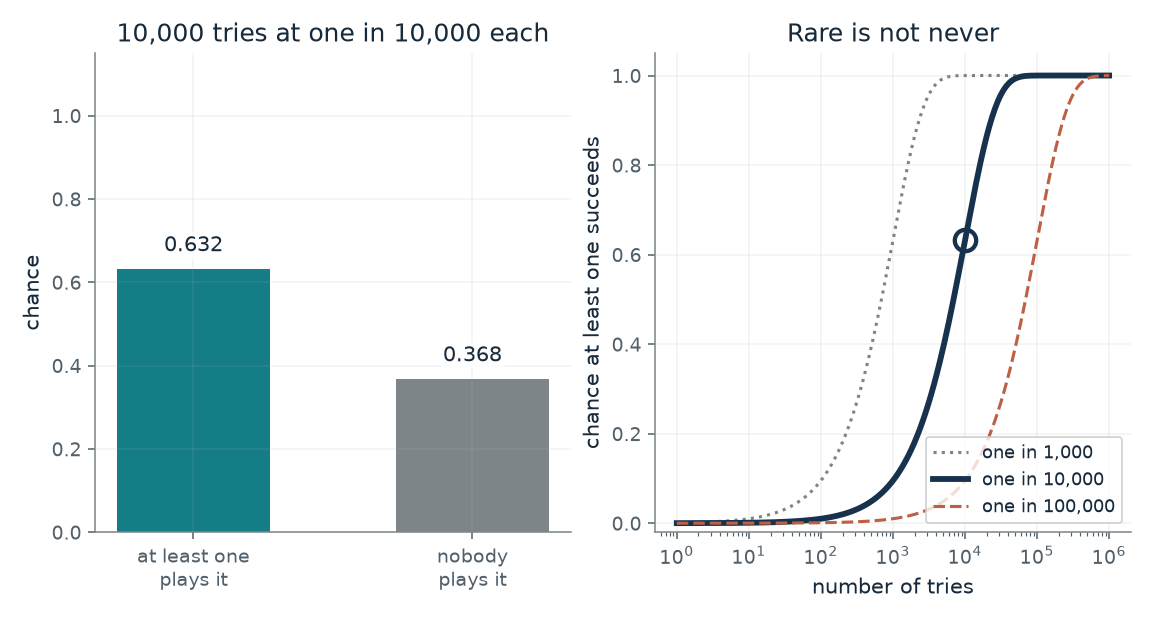

- **Chance at least one plays it:** 0.632
- **Chance nobody does:** 0.368
- **Expected number of players:** 1
- **Tries for a 50 percent chance:** 6,932

With a one-in-10,000 chance per try, 10,000 independent tries give a 0.632 chance that at least one succeeds. A small chance per try does not mean it never happens; it means it takes many tries.

P(at least one) = 1 - (1 - p)^n = 1 - (1 - 1/10,000)^10,000 = 0.632. Tries for a 50 percent chance: ln(0.5)/ln(1 - p) = 6,932.

In [2]:
figure, values, explanation = rare_move_picture(**{'n': 10000, 'odds': 10000})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Is a one-in-ten-thousand move a move no human would play?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of independent tries = 10000, Chance per try is one in = 10000: After 10,000 tries at one in 10,000, the chance that at least one succeeds is about 0.632. Half the chance is reached near 6,931 tries. A rare chance is not never; the chapter makes the same point: a one-in-ten-thousand chance is not never.

**Takeaway:** A small chance per try compounds. With enough tries, the 'impossible' move shows up.

**Why it matters:** A claim of novelty from a probability is a claim about one estimate of one position, not a statement that the move never occurred. Separating the two keeps novelty from sliding into originality.

**In machines:** AlphaGo's figure is the program's own estimate of how humans play, a model of human moves. The sources report it as an estimate, not as a count of games.

**Where it applies:** The tries are independent and each has the same chance. The estimate belongs to one position as AlphaGo judged it. The number of times humans face that position is not given anywhere in the chapter.

**Check your understanding:** At a chance of one in 1,000 per try, how many tries give a better-than-even chance that at least one succeeds?

<details><summary>Show the answer</summary>

ln(0.5)/ln(0.999) is about 692.8, so 693 tries give a chance a little above one half.

</details>

*Source: Chapter 12, A paper from before the match says how the program was built. The 1 in 10,000 figure is the chapter's quote: AlphaGo's own estimate of the chance a human would play move 37, reported by Wired and repeated by DeepMind's page. The numbers of tries are made up. The formula is the companion's arithmetic on that quote, not a claim in the chapter.*

## C12-D02: How long does it take to turn a shape in the mind?

If reaction time rises in a straight line from 1 second at no turn to 4 to 6 seconds at a half turn, what turning speed does the line imply?

If a mind rotated the shape at a steady speed, a turn twice as large would take twice as long, plus a fixed time for everything else. That is the straight line. Its slope is time per degree, and the inverse of the slope is degrees per second. The rate holds only if the process really is a turning.

$$
T(\theta)=T_0+\frac{T_{180}-T_0}{180}\,\theta,\qquad \text{rate}=\frac{180}{T_{180}-T_0}
$$

**Symbols:** theta: the angle between the two drawings, in degrees; T_0: reaction time with no turn, about 1 second; T_180: reaction time at a half turn, 4 to 6 seconds depending on the person; rate: degrees of imagined turning per second implied by the slope

**Predict before looking:** If the line runs from 1 second to 4 seconds, predict the time for a quarter turn (90 degrees), then check.

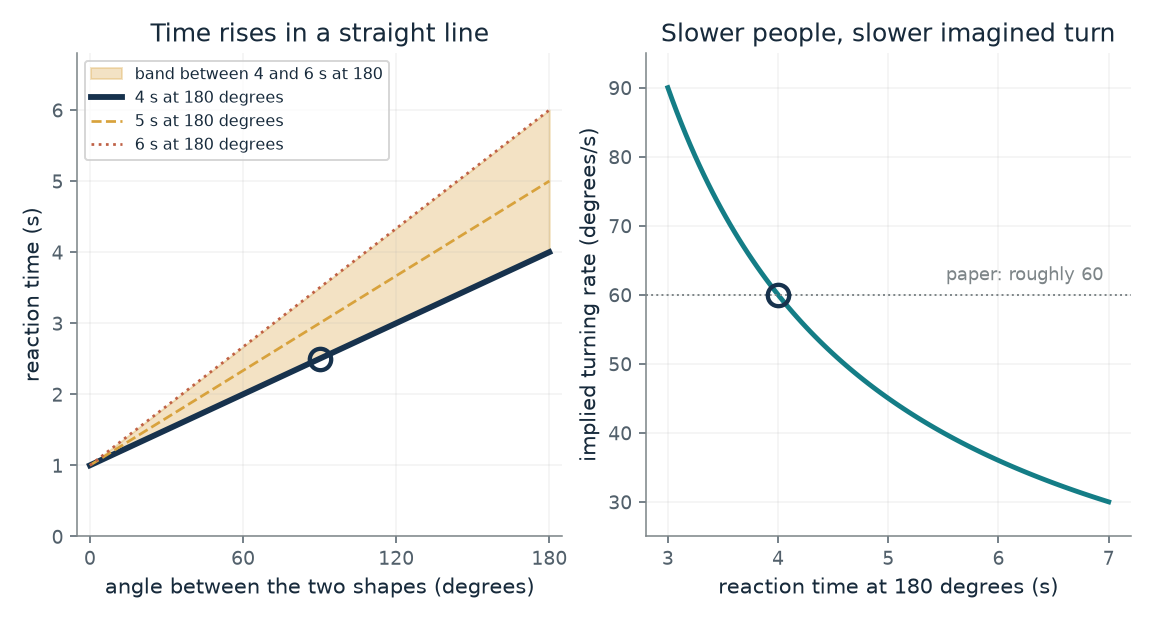

- **Predicted reaction time (s):** 2.5
- **Time added by the turn (s):** 1.5
- **Turning rate implied (degrees/s):** 60
- **Reaction time with no turn (s):** 1

Joining 1 s at no turn to 4 s at a half turn, a 90 degree turn takes 2.5 s. The line's slope implies 60 degrees of imagined turning per second, and the paper's rate is roughly 60.

Time = 1 + (4 - 1) x 90/180 = 2.5 s. Rate = 180/(4 - 1) = 60 degrees per second.

In [3]:
figure, values, explanation = rotation_picture(**{'angle': 90, 'time_at_180': 4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How long does it take to turn a shape in the mind?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Angle between the shapes (degrees) = 90, Reaction time at a half turn (s) = 4: The quarter turn takes 1 + 3 x 90/180 = 2.5 seconds. The line from 1 to 4 seconds implies 60 degrees per second, which matches the rate the chapter quotes. A person near the 6 second end turns about 36 degrees per second on the same reading.

**Takeaway:** A straight line of time against angle is what you would expect if the mind turned the shape at a steady rate.

**Why it matters:** The simplest picture of imagining is a model of how things move, run on a case that is not happening. The straight line is behavior that fits that picture; it does not show how a brain does the turning.

**In brains and behavior:** The eight adults showed a straight-line rise in reaction time and said they imagined turning the shape. The paper has no brain data, and the rate is a summary of behavior.

**In machines:** A world model runs a learned rule forward step by step. The straight line is the cost of a mind doing something like that, in time, which the next demonstration treats as a computation.

**Where it applies:** Time is a straight line in angle between the quoted end points. The paper has no brain data. All subjects said they imagined one shape turning, and the authors treat such reports with caution. Joining 1 and 4 seconds gives the paper's 60; joining 1 and 6 seconds gives 36.

**Check your understanding:** A person takes 1 second at no turn and 5 seconds at a half turn. How long should a 135 degree turn take, and what turning rate is that?

<details><summary>Show the answer</summary>

Time = 1 + 4 x 135/180 = 4 seconds. The rate is 180/4 = 45 degrees per second.

</details>

*Source: Chapter 12, Eight adults, 1,600 pairs of shapes each, and a straight line. Reported result (Shepard and Metzler, 1971, as the chapter presents it): eight adults, 1,600 pairs each, correct same-shape answers about 1 second at no turn and 4 to 6 seconds at a half turn. The straight lines here join the chapter's end points, as the chapter's figure does; the chapter's rate of roughly 60 degrees per second is the paper's.*

## C12-D03: How far can an imagined run be trusted?

A model rolls an imagined ball forward step by step. If its rule is slightly wrong, how large is the error after many steps?

At each step the model starts from its own last answer, not from the true state. So the imagined position and the real position part company at step one and the gap itself gets multiplied. The numbers show the idea in the simplest rule I could build; real models are noisier and predict ranges.

$$
s_{t+1}=f(s_t,a_t)
$$

**Symbols:** s_t: the state: the ball's position at step t; a_t: the action: a choice at step t (here, move right by 2); f: the model's rule; the real rule is s + a, the imagined one is gain x s + a

**Predict before looking:** If the model's gain is 1.05 and it runs 10 steps, predict whether the imagined ball is off by a little, or by a lot compared with how far it has moved.

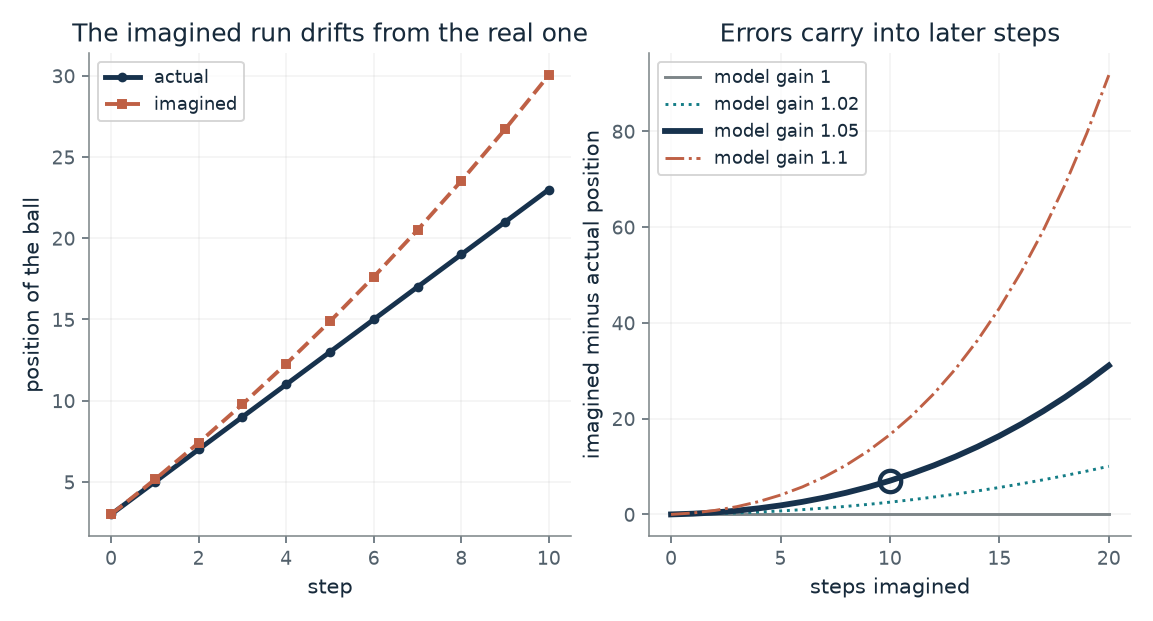

- **Imagined position:** 30
- **Actual position:** 23
- **Error:** 7.04
- **Error against distance moved:** 35.2 percent

Starting at 3 and choosing to move right by 2 each step, the real ball is at 23 after 10 steps. A model whose rule is off by gain 1.05 imagines it at 30, an error of 7.04.

Real step: s_next = s + 2, so s after 10 steps = 3 + 2 x 10 = 23. Imagined step: s_next = 1.05 x s + 2, applied 10 times, gives 30.

In [4]:
figure, values, explanation = rollout_picture(**{'gain': 1.05, 'steps': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far can an imagined run be trusted?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Model's gain (1 is the correct rule) = 1.0, Steps imagined = 1: With a correct rule, one step takes the ball from 3 to 5, the chapter's example. Now raise the gain and the steps: the error is small after one step and keeps growing, because each imagined step starts from an already wrong place.

**Takeaway:** An error in the model carries into every later step, so a small mismatch can grow into a large one.

**Why it matters:** A machine that trains on imagined games inherits the model's flaws. In the world-model experiment the agent scored 2,086 out of 2,100 in its dream and 193 in the real game, against 210 for random play. The real game exposed what the dream hid.

**In brains and behavior:** If imagining is running a model forward, errors would carry through the run too. The chapter's studies do not show how a brain would do that, or how a brain's own model errors grow.

**In machines:** This rule is a specification: the program applies a function again and again. In a learned world model that function is learned from experience, and its errors are what the rollout inherits.

**Where it applies:** One number for the state, the same action each step, and a model whose only flaw is a gain above 1. A real learned model has many flaws and predicts a range of outcomes.

**Check your understanding:** With gain 1.1 and 2 steps from 3, what is the imagined position, and what is the real one?

<details><summary>Show the answer</summary>

Imagined: step 1 gives 1.1 x 3 + 2 = 5.3; step 2 gives 1.1 x 5.3 + 2 = 7.83. Real: 3 + 2 + 2 = 7. The error is 0.83.

</details>

*Source: Chapter 12, Eight adults, 1,600 pairs of shapes each, and a straight line. Constructed example. The ball at position 3 and the choice 'move right by 2' (giving 5) are the chapter's illustration. The wrong rule, with a gain above 1, is the companion's own invention to show an error carrying into later steps; it is not Ha and Schmidhuber's model, which predicts a range of outcomes and carries a memory.*

## C12-D04: Why does the option a scorer picks look better than it is?

A scorer ranks imagined options, and the highest score is chosen. How much does the chosen option's score overstate its worth?

A high score comes partly from real worth and partly from luck in the scoring. Picking the highest score picks the luckiest as well as the best, so on average the pick's true value is less than its score. Both the number of candidates and the scorer's roughness make the pick more selected for luck.

$$
\text{true value of the pick}=\frac{m_n}{\sqrt{1+\sigma^2}},\qquad \text{score of the pick}=m_n\sqrt{1+\sigma^2}
$$

**Symbols:** n: number of candidates; m_n: the average best true value among n candidates (candidate values have spread 1); sigma: spread of the scorer's error, in the same units

**Predict before looking:** With 10 candidates and a scorer whose error is as large as the spread of the candidates (sd 1), predict whether the scorer's claim for its pick is higher than the pick's true value, and by how much.

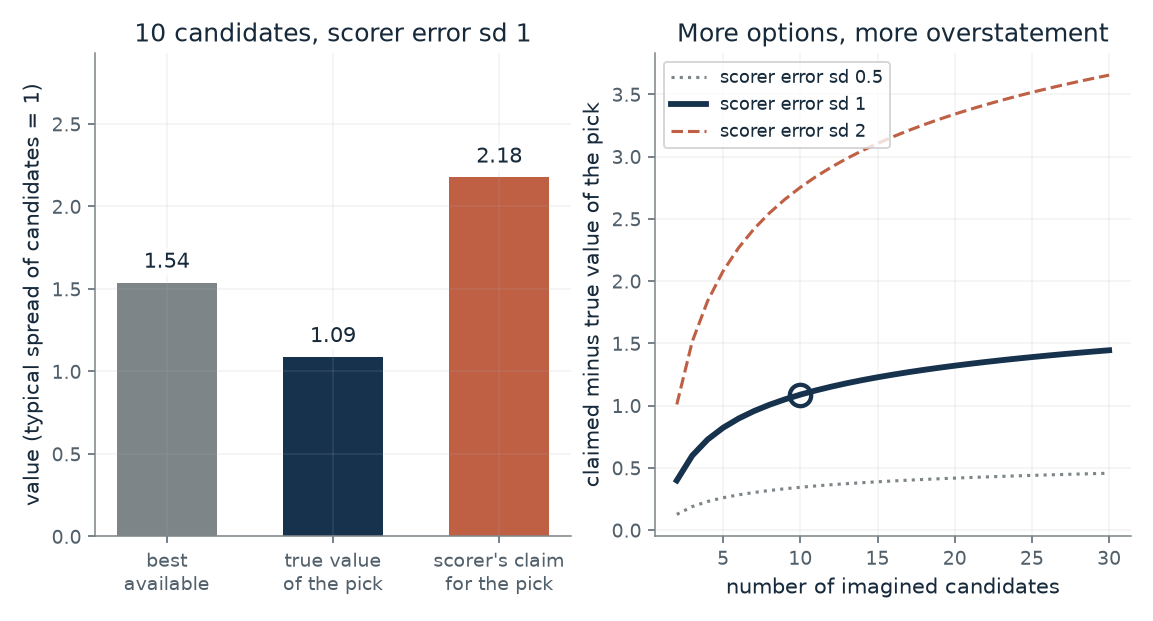

- **Best available (mean):** 1.54
- **True value of the pick:** 1.09
- **Scorer's claim for the pick:** 2.18
- **Overstatement:** 1.09

With 10 candidates and scorer error sd 1, the pick's true value averages 1.09 against 1.54 for the best on offer. The scorer claims 2.18, because the pick was chosen partly for its scoring error.

Mean best of 10 standard normal values = 1.54. True value of the pick = 1.54/sqrt(1 + 1^2) = 1.09. Claim = 1.54 x sqrt(1 + 1^2) = 2.18.

In [5]:
figure, values, explanation = scorer_picture(**{'candidates': 10, 'scorer_sd': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does the option a scorer picks look better than it is?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of imagined candidates = 10, Scorer error sd = 1.0: With 10 candidates and scorer error sd 1, the pick's true value averages about 1.09 and the scorer claims about 2.18. The scorer is unbiased overall, but the pick was chosen partly for its good luck in scoring, so its score overstates its worth.

**Takeaway:** The highest-scored option is selected for its error as well as its worth, so its score overstates it, more so with more options and a rougher scorer.

**Why it matters:** Imagining generates options; something must rank them. The chapter's world-model agent excelled against its own inaccurate dream and failed in the real game. A check in the setting where the idea will be used is what separates the claimed worth from the real one.

**In brains and behavior:** The chapter says nothing in these studies shows what stands in for a scoreboard when a person imagines alone.

**In machines:** A machine that generates many candidates and picks the top-scored one inherits this overstatement, which the real game, a reader's rating or a person's judgment can expose.

**Where it applies:** Candidate values and scorer errors are bell-shaped, the scorer is unbiased, and its error is unrelated to the candidate. A flawed scorer in a real game has systematic flaws that an agent can find, which this model does not capture; it shows only the smallest version of the effect.

**Check your understanding:** Three moves are scored 2, 5 and 4, and the second is chosen. If the scorer's error could be as large as 1 point, can the choice be wrong?

<details><summary>Show the answer</summary>

Yes. The second and third moves are only 1 point apart, so an error of 1 can reverse them. The first move is 3 points behind, so it is much less likely to win by error.

</details>

*Source: Chapter 12, Eight adults, 1,600 pairs of shapes each, and a straight line. Constructed model. The chapter's own example is three moves with scores 2, 5 and 4, where the second is chosen. The closed forms here follow from standard normal values and normal scoring error; they are the companion's addition. The chapter's dream-versus-real figures (2,086 of 2,100 imagined, 193 real, 210 random) are quoted from it and are not produced here.*

## C12-D05: How do sums on points make a smiling man?

If smiling woman minus neutral woman plus neutral man gives a smiling man, why does the chapter say that averaging three faces per idea mattered?

Each idea is the average of a few example points, so its error is smaller than one example's by the square root of the number averaged. The sum has three such averages and three numbers, so its typical miss is 3 times the scatter divided by the square root of the number of examples.

$$
x=g(z),\qquad z_{\text{smiling man}}\approx \bar z_{\text{smiling woman}}-\bar z_{\text{neutral woman}}+\bar z_{\text{neutral man}}
$$

**Symbols:** z: a point in the latent space (the toy has three numbers; the real one has 100); g: the generator: it turns a point into an image; z-bar: the average of the points for several example faces of one idea

**Predict before looking:** With face scatter 1, predict whether averaging 3 faces per idea gives a typical miss of the target below 1, then check.

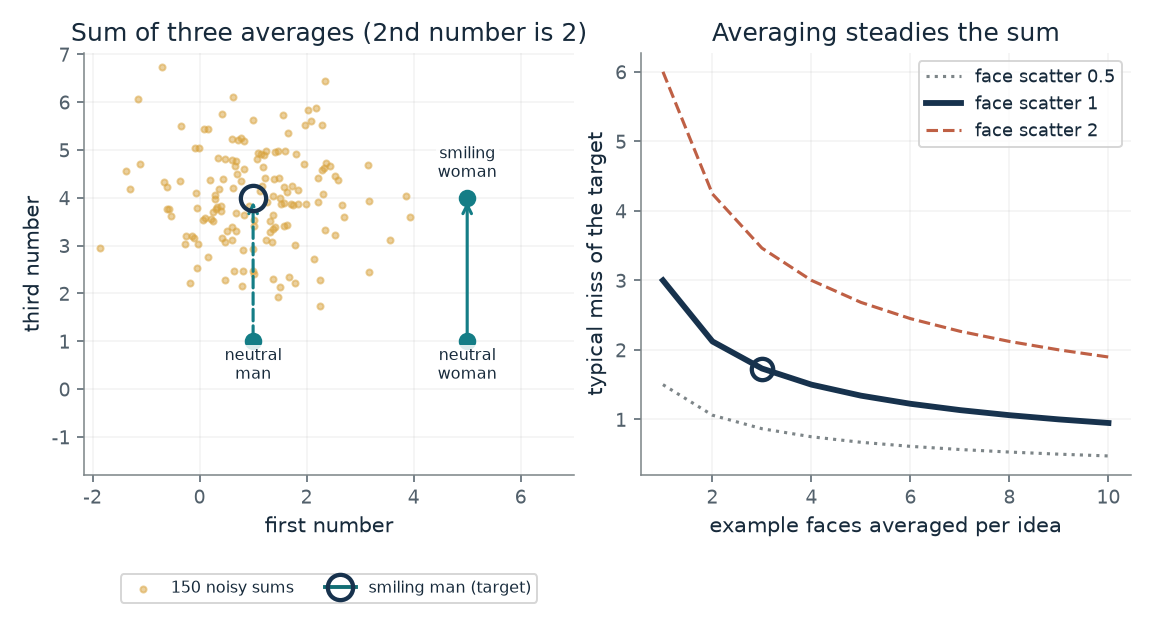

- **Noise-free result:** (1, 2, 4)
- **Typical miss, exact:** 1.73
- **Typical miss in the 150 draws:** 1.79
- **Miss against the smile step of 3:** 0.577

Without scatter, smiling woman minus neutral woman plus neutral man lands exactly on (1, 2, 4), the smiling man. With face scatter 1 and 3 examples per idea, the result misses by about 1.73 on average, in made-up numbers.

(5, 2, 4) - (5, 2, 1) + (1, 2, 1) = (1, 2, 4). Each idea's average has scatter 1/sqrt(3); three averages and three numbers give a typical miss of sqrt(9) x 1/sqrt(3) = 1.73.

In [6]:
figure, values, explanation = latent_picture(**{'examples': 3, 'spread': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How do sums on points make a smiling man?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Example faces averaged per idea = 3, Scatter of example faces = 1.0: Without scatter the sum lands exactly on (1, 2, 4). With scatter 1 and 3 examples per idea the typical miss is 3 x 1/sqrt(3), about 1.73, still more than half the smile step of 3. With one example it is 3, as large as the step itself.

**Takeaway:** Averaging several example faces per idea steadies the arithmetic. The sum is exact only when the points are exact.

**Why it matters:** A step along the space that changes one feature is only as reliable as the points it starts from. The chapter's authors also never tested whether a new face sits far from its closest training face, so the sums do not show the faces are original.

**In brains and behavior:** The sources here show no brain counterpart to such a space.

**In machines:** A generator turns each point into an image, so a point is enough to get a face. The toy sum is a specification of vector arithmetic; whether a real space follows it is shown only for selected paths, not everywhere.

**Where it applies:** Each example face is its idea's point plus independent bell-shaped scatter of the same size in every number. The chapter reports no such scatter. Real spaces are less tidy, and the sums were a demonstration in one figure, not a measured success rate.

**Check your understanding:** With scatter 2 and 4 examples per idea, what is the typical miss of the target?

<details><summary>Show the answer</summary>

3 x 2/sqrt(4) = 3. The same miss as one example with scatter 1, because four examples halve the scatter of 2 to 1 per number.

</details>

*Source: Chapter 12, A network learned to turn points into faces. The toy points (5, 2, 4), (5, 2, 1) and (1, 2, 1) giving (1, 2, 4) are the chapter's illustration with made-up numbers. The scatter of example faces and the 150 seeded draws (seed 12) are the companion's constructed model of why averaging helps; the chapter reports only that one example per idea was 'unstable' and three averaged examples worked. They are not measurements of a network.*

## C12-D06: What did machine ideas do for the writers?

How much higher did readers rate stories written with machine ideas, and for which writers was the gain largest?

Writers with no ideas set the zero. With one idea, readers rated the writers' stories higher on both indices, and with up to five, higher still. The authors found little effect for writers who scored high on the word-association test.

$$
\text{gain}=\frac{\text{rating with ideas}-\text{rating without}}{\text{rating without}}\times 100
$$

**Symbols:** gain: percent change in the readers' index, against writers with no machine ideas; novelty index: readers' rating of a story as novel, original and rare; usefulness index: readers' rating as appropriate, feasible and publishable

**Predict before looking:** Before you choose, predict whether the usefulness gain is larger with one idea or with up to five, and whether it grows faster than the novelty gain.

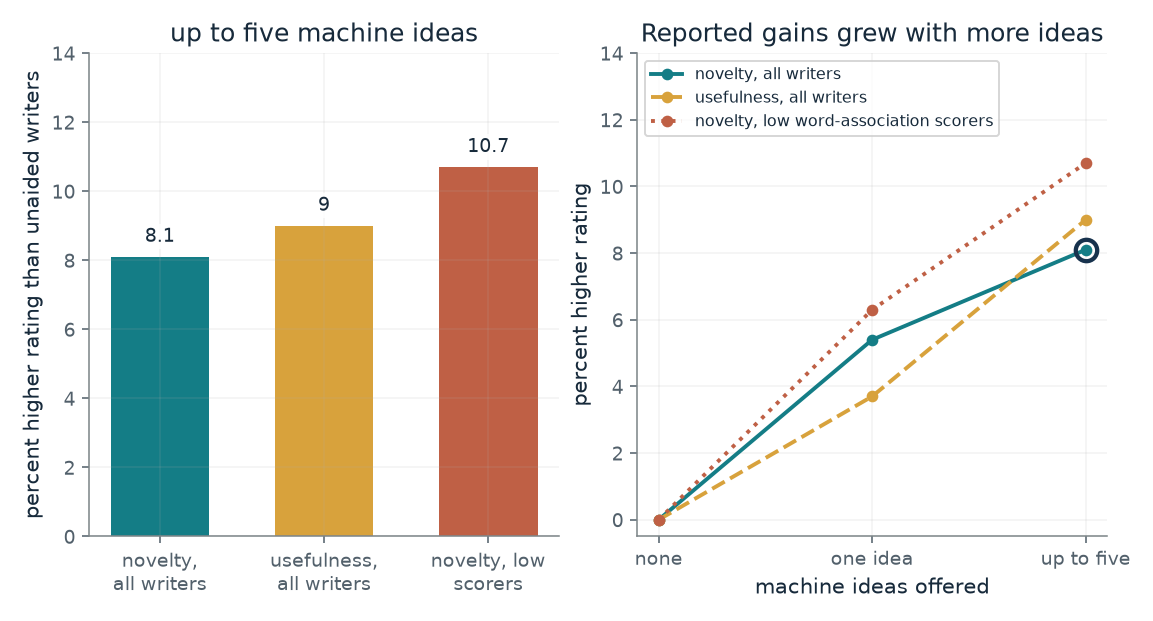

- **Novelty gain, all writers (percent):** 8.1
- **Usefulness gain, all writers (percent):** 9
- **Novelty gain, low scorers (percent):** 10.7

Readers rated stories by writers offered up to five machine ideas higher by 8.1 percent on novelty and 9 percent on usefulness. For writers who scored low on the word-association test, the novelty gain was 10.7 percent.

These are the chapter's reported percentages, read from the chapter and not recomputed from the study's data.

In [7]:
figure, values, explanation = writers_picture(**{'ideas': 5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What did machine ideas do for the writers?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Machine ideas offered (0 = none, 1 = one, 5 = up to five) = 5: With up to five ideas, novelty rose 8.1 percent and usefulness 9.0. Usefulness grew from 3.7 to 9.0 percent, more than the novelty gain did. The low scorers gained 10.7 percent on novelty.

**Takeaway:** Access to machine ideas went with higher ratings of novelty and usefulness, most for writers who scored low on the word-association test.

**Why it matters:** This covers two of the three tests from move 37, with readers scoring novelty and usefulness separately. It shows that people can be helped; it does not show that a brain generates candidates the same way.

**In brains and behavior:** Readers' ratings played the part of the scoreboard. The study did not test how the writers themselves generate ideas.

**In machines:** GPT-4 supplied three-sentence ideas. The model's side is a source of candidates, rated by people afterward.

**Where it applies:** Writers were recruited online without selection for writing experience and the task was an eight-sentence story. Originality was not rated on its own; it sits inside the novelty rating. Novelty and usefulness were scored apart.

**Check your understanding:** In the study, did novelty or usefulness gain more going from one idea to up to five, and by how many percentage points?

<details><summary>Show the answer</summary>

Novelty went from 5.4 to 8.1, a rise of 2.7 points. Usefulness went from 3.7 to 9.0, a rise of 5.3 points, so usefulness gained more.

</details>

*Source: Chapter 12, Writers with AI story ideas, and stories that look alike. Reported result, quoted from the chapter (Doshi and Hauser, 2024): 293 writers, 600 readers. One idea: novelty up 5.4 percent, usefulness up 3.7. Up to five: 8.1 and 9.0. Low word-association scorers: novelty up 6.3 and 10.7 percent. The chapter gives no usefulness figures for the low scorers and no number for high scorers ('little effect'), so none appear here.*

## C12-D07: When does a shared source narrow what people write?

If some writers build on ideas from one source, when does the whole pool of stories get narrower?

The pool is a mixture of two groups. Its variance is the share-weighted average of their variances, because both groups are centered at the same place in this model. When the machine's ideas are no narrower than the writers' own, the pool's spread stays at 1. Only a narrower source shrinks it.

$$
\sigma_{\text{pool}}=\sqrt{(1-q)\,\sigma_w^{2}+q\,\sigma_i^{2}}
$$

**Symbols:** q: the share of writers who build on a machine idea; sigma_w: spread of stories writers produce alone (set to 1); sigma_i: spread of stories built on the machine's ideas; sigma_pool: spread of the whole pool of stories

**Predict before looking:** If the machine's ideas are as varied as the writers themselves (spread 1), predict how much the pool narrows when most writers use them.

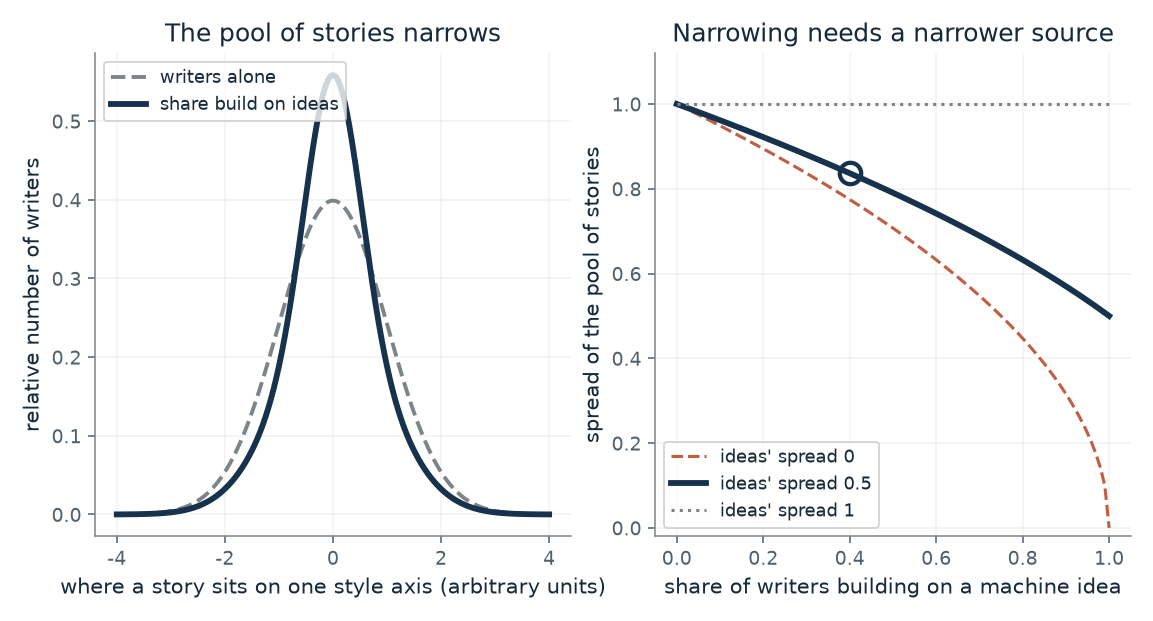

- **Spread of the pool:** 0.837
- **Spread of writers alone:** 1
- **Pool spread as a share of writers alone:** 0.837
- **Share building on ideas:** 0.4

If 0.4 of writers build on ideas whose spread is 0.5 and the rest write alone with spread 1, the pool's spread is 0.837. Only a source narrower than the writers shrinks the pool, and the model says nothing about how good any story is.

Spread = sqrt((1 - 0.4) x 1^2 + 0.4 x 0.5^2) = 0.837.

In [8]:
figure, values, explanation = anchoring_picture(**{'share': 0.4, 'idea_spread': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When does a shared source narrow what people write?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of writers building on a machine idea = 0.4, Spread of the machine's ideas = 0.5: With 0.4 of writers building on ideas of spread 0.5, the pool's spread falls to about 0.84. Set the ideas' spread to 1 and the pool does not narrow at all, however many use them. Set it to 0 and the share building on the one idea becomes a spike.

**Takeaway:** A shared source narrows the pool only if it is narrower than the writers it feeds.

**Why it matters:** A person can be helped while the pool of ideas narrows. Whether a machine source is narrower than its users is a measurable question, which the study's main text did not test.

**In brains and behavior:** The study measured stories, not the minds that produced them.

**In machines:** A model draws on one learned source for every user. This demonstration shows what such a source would do if its spread were smaller; it does not show that it is.

**Where it applies:** Each writer either builds on a machine idea or writes alone, with story positions bell-shaped on a single arbitrary axis. A program measured similarity in the study, with embeddings, not this axis. The model says nothing about how good any story is.

**Check your understanding:** Half of the writers build on ideas with spread 0, all the same, and the rest write alone with spread 1. What is the pool's spread?

<details><summary>Show the answer</summary>

sqrt(0.5 x 1 + 0.5 x 0) = sqrt(0.5), about 0.707.

</details>

*Source: Chapter 12, Writers with AI story ideas, and stories that look alike. Model, the companion's own. The chapter calls the machine side an inference: a model may repeat its favorite patterns because its output comes from one learned source, and the study did not test that in its main text. The measured rise in similarity was small: under one point on a scale whose own range was about 8 points, and about 5 percent more similar to the machine's ideas. This demonstration does not reproduce those figures.*

## Bring it to your own question

Ask what the candidates were generated from, what scores them, and what independent check exists in the setting where the idea will be used. Report novelty, usefulness and originality separately, say which was tested, and name the one that was not. Treat a model of the world as a source of candidates, not as the world, and expect its errors to grow with each step imagined.

Use the `mmi-ch12-imagining-new` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.